# Vision Transformer (ViT)

**Paper:** A. Dosovitskiy, L. Beyer, A. Kolesnikov, D. Weissenborn, X. Zhai, T. Unterthiner, M. Dehghani, M. Minderer, G. Heigold, S. Gelly, J. Uszkoreit, and N. Houlsby, "An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale," in *International Conference on Learning Representations (ICLR)*, 2021. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)

**Summary:** ViT applies a pure Transformer encoder to sequences of fixed-size image patches with minimal inductive bias, showing that large-scale pre-training enables transformers to match or exceed CNN performance on image recognition.

> 📄 **Paper:** Dosovitskiy et al. (2021). An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale. ICLR 2021.
> 🔗 **Link:** <https://arxiv.org/abs/2010.11929>
> 🧩 **Implementation:** `hale_core/nn/vision/vit/vit.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> PE["PatchEmbed: conv 16×16 /16 → (B, 196, D)"]:::stage
  PE --> CLS["prepend [CLS] · + learned position embedding"]:::stage --> ENC["L × Transformer block"]:::stage --> NORM["LayerNorm"]:::block
  NORM --> POOL["pooled = CLS token"]:::block --> OUT
  subgraph TB["pre-norm Transformer block"]
    direction LR
    X["x"] --> LN1["LN"]:::block --> MSA["multi-head self-attention"]:::block --> A1(("+"))
    X --> A1 --> LN2["LN"]:::block --> MLP["MLP 4D · GELU"]:::block --> A2(("+"))
    A1 --> A2
  end
  ENC -.-> TB
  OUT["BackboneOutput<br/>pooled_output (B, D)<br/>patch_tokens (B, N, D)<br/>feature_maps [(B, D, H/p, W/p)]"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input Image [B, 3, H, W]
        │
        ▼  PatchEmbed (Conv2d, kernel=patch_size, stride=patch_size)
Patches [B, N, D]   where N = (H/p)*(W/p)
        │
        ▼  Prepend CLS token → cat([cls, patches]) → shape [B, N+1, D]
        │  Add learned 1D positional embedding (one vector per token)
        │
        ▼  ┌─────────────────────────────────────┐
           │  ViTBlock × depth                   │
           │  ┌────────────────────────────────┐ │
           │  │  x = x + Attn(LayerNorm(x))   │ │  ← Pre-norm
           │  │  x = x + MLP(LayerNorm(x))    │ │
           │  │  Attn: Q,K,V via single in_proj│ │
           │  │  MLP:  Linear→GELU→Linear 4×  │ │
           │  └────────────────────────────────┘ │
           └─────────────────────────────────────┘
        │
        ▼  Final LayerNorm
        │
        ├──► pooled_output = x[:, 0]       [B, D]      (CLS token)
        └──► patch_tokens  = x[:, 1:]      [B, N, D]
             feature_maps  = reshape(patch_tokens) → [B, D, H/p, W/p]
```

### Key Design Decisions
| Choice | Value | Reason |
|--------|-------|--------|
| Pre-norm | LN before residual branch | More stable than post-norm at scale |
| Positional encoding | Learned 1D absolute | Simple; 2D or RoPE used by later models |
| Pooling | CLS token | Dedicated summary token; patch tokens remain spatial |
| MLP activation | GELU | Smoother than ReLU; marginal gains at scale |
| QKV projection | Single `in_proj` (3D→3×D) | Cache-friendly, matches NLP Transformer |

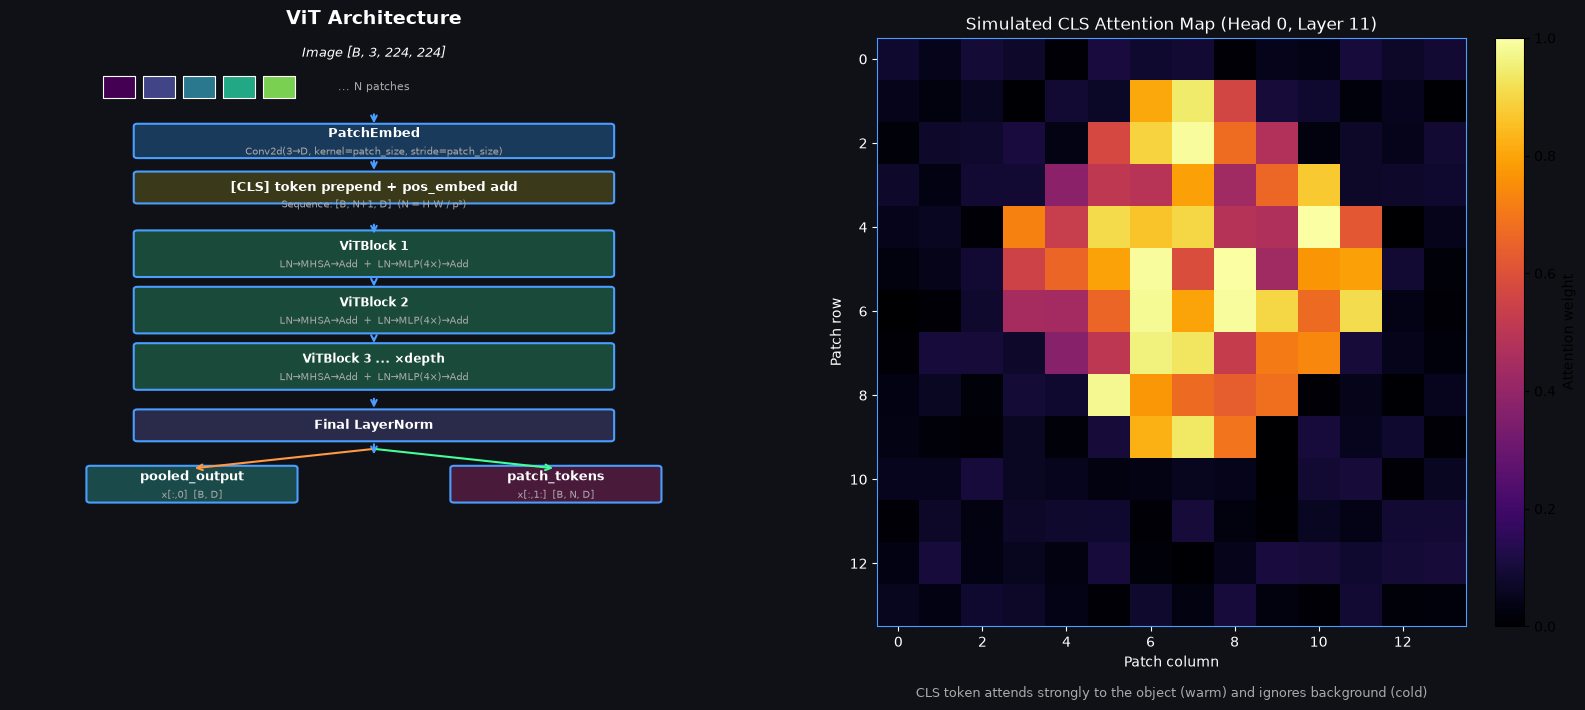

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor('#0f1117')

# ── Left: ViT Architecture Diagram ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#0f1117')
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis('off')
ax.set_title('ViT Architecture', color='white', fontsize=14, fontweight='bold', pad=10)

BOX_CLR = {'embed': '#1a3a5c', 'block': '#1a4a3a', 'cls': '#4a1a3a',
           'pos': '#3a3a1a', 'norm': '#2a2a4a', 'out': '#1a4a4a'}
TXT = 'white'

def draw_box(ax, x, y, w, h, label, sublabel='', color='#1a3a5c', fontsize=9):
    box = FancyBboxPatch((x - w/2, y - h/2), w, h,
                          boxstyle='round,pad=0.05', facecolor=color,
                          edgecolor='#4a9eff', linewidth=1.5)
    ax.add_patch(box)
    ax.text(x, y + (0.15 if sublabel else 0), label, ha='center', va='center',
            color=TXT, fontsize=fontsize, fontweight='bold')
    if sublabel:
        ax.text(x, y - 0.22, sublabel, ha='center', va='center',
                color='#aaaaaa', fontsize=7)

def arrow(ax, x, y1, y2, color='#4a9eff'):
    ax.annotate('', xy=(x, y2 + 0.05), xytext=(x, y1 - 0.05),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

# Image patches
for i, (xi, yi) in enumerate([(1.5+j*0.55, 11) for j in range(5)]):
    c = FancyBboxPatch((xi-0.22, yi-0.22), 0.44, 0.44,
                        boxstyle='square,pad=0', facecolor=plt.cm.viridis(i/5),
                        edgecolor='white', linewidth=0.8)
    ax.add_patch(c)
ax.text(5, 11, '... N patches', ha='center', va='center', color='#aaaaaa', fontsize=8)
ax.text(5, 11.7, 'Image [B, 3, 224, 224]', ha='center', va='center', color=TXT, fontsize=9, style='italic')

arrow(ax, 5, 10.55, 10.15)
draw_box(ax, 5, 9.9, 6.5, 0.6, 'PatchEmbed', 'Conv2d(3→D, kernel=patch_size, stride=patch_size)', BOX_CLR['embed'])

arrow(ax, 5, 9.6, 9.2)
draw_box(ax, 5, 8.95, 6.5, 0.55, '[CLS] token prepend + pos_embed add', '', BOX_CLR['pos'])
ax.text(5, 8.6, 'Sequence: [B, N+1, D]  (N = H·W / p²)', ha='center', va='center',
        color='#aaaaaa', fontsize=7.5)

arrow(ax, 5, 8.3, 7.9)
# Stacked ViT blocks
for i in range(3):
    y_blk = 7.6 - i * 1.15
    draw_box(ax, 5, y_blk, 6.5, 0.85,
             f'ViTBlock {i+1}' + (' ... ×depth' if i == 2 else ''),
             'LN→MHSA→Add  +  LN→MLP(4×)→Add', BOX_CLR['block'], fontsize=8.5)
    if i < 2:
        arrow(ax, 5, y_blk - 0.47, y_blk - 0.78)

arrow(ax, 5, 4.75, 4.35)
draw_box(ax, 5, 4.1, 6.5, 0.55, 'Final LayerNorm', '', BOX_CLR['norm'])

arrow(ax, 5, 3.82, 3.4)
# Two outputs
draw_box(ax, 2.5, 2.9, 2.8, 0.65, 'pooled_output', 'x[:,0]  [B, D]', BOX_CLR['out'])
draw_box(ax, 7.5, 2.9, 2.8, 0.65, 'patch_tokens', 'x[:,1:]  [B, N, D]', BOX_CLR['cls'])
ax.annotate('', xy=(2.5, 3.22), xytext=(5, 3.62),
            arrowprops=dict(arrowstyle='->', color='#ff9944', lw=1.5))
ax.annotate('', xy=(7.5, 3.22), xytext=(5, 3.62),
            arrowprops=dict(arrowstyle='->', color='#44ff99', lw=1.5))

# ── Right: Attention heatmap visualization ───────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#0f1117')
ax2.set_title('Simulated CLS Attention Map (Head 0, Layer 11)', color='white', fontsize=12)

# Generate a plausible-looking attention map: high attention on object, low on bg
rng = np.random.default_rng(42)
grid = 14  # 224/16
attn_map = rng.random((grid, grid)) * 0.1
# Create a circular object region with high attention
yy, xx = np.ogrid[:grid, :grid]
mask = (xx - 7)**2 + (yy - 5)**2 < 18
attn_map[mask] += rng.random(mask.sum()) * 0.6 + 0.3
attn_map /= attn_map.sum()
attn_map = attn_map / attn_map.max()

im = ax2.imshow(attn_map, cmap='inferno', interpolation='nearest', vmin=0, vmax=1)
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label='Attention weight')
ax2.set_xlabel('Patch column', color='white')
ax2.set_ylabel('Patch row', color='white')
ax2.tick_params(colors='white')
for spine in ax2.spines.values():
    spine.set_edgecolor('#4a9eff')

ax2.text(0.5, -0.12,
         'CLS token attends strongly to the object (warm) and ignores background (cold)',
         transform=ax2.transAxes, ha='center', color='#aaaaaa', fontsize=9)

plt.tight_layout()

plt.show()

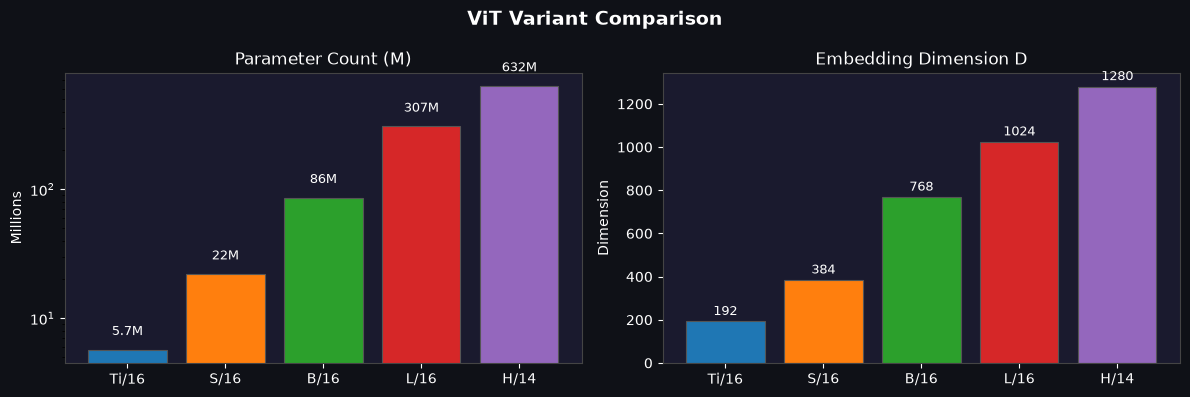

In [2]:
# ── Variant comparison chart ─────────────────────────────────────────────────
import matplotlib.ticker as mticker

variants = {
    'Ti/16': {'params_M': 5.7,  'dim': 192,  'heads': 3,  'depth': 12},
    'S/16':  {'params_M': 22,   'dim': 384,  'heads': 6,  'depth': 12},
    'B/16':  {'params_M': 86,   'dim': 768,  'heads': 12, 'depth': 12},
    'L/16':  {'params_M': 307,  'dim': 1024, 'heads': 16, 'depth': 24},
    'H/14':  {'params_M': 632,  'dim': 1280, 'heads': 16, 'depth': 32},
}

names = list(variants.keys())
params = [v['params_M'] for v in variants.values()]
dims   = [v['dim']      for v in variants.values()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.patch.set_facecolor('#0f1117')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for ax in [ax1, ax2]:
    ax.set_facecolor('#1a1a2e')
    ax.tick_params(colors='white')
    for sp in ax.spines.values():
        sp.set_edgecolor('#444')

ax1.bar(names, params, color=colors, edgecolor='#555', linewidth=0.8)
ax1.set_title('Parameter Count (M)', color='white', fontsize=12)
ax1.set_ylabel('Millions', color='white')
ax1.set_yscale('log')
for i, (n, p) in enumerate(zip(names, params)):
    ax1.text(i, p * 1.3, f'{p}M', ha='center', color='white', fontsize=9)

ax2.bar(names, dims, color=colors, edgecolor='#555', linewidth=0.8)
ax2.set_title('Embedding Dimension D', color='white', fontsize=12)
ax2.set_ylabel('Dimension', color='white')
for i, (n, d) in enumerate(zip(names, dims)):
    ax2.text(i, d + 30, str(d), ha='center', color='white', fontsize=9)

fig.suptitle('ViT Variant Comparison', color='white', fontsize=14, fontweight='bold')
plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations

### 1. Pure Transformer for Vision
Prior work (e.g., BERT for NLP) showed transformers excel at sequences. ViT asks: *can we apply the same architecture to images with minimal modification?*

The answer: **yes**, if pre-trained at sufficient scale (JFT-300M, ImageNet-21k). At smaller scales (ImageNet-1k alone), CNNs still have an advantage due to their translation equivariance inductive bias.

### 2. Scaled Dot-Product Attention

$$\text{Attn}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_{head}}}\right)V$$

- $Q, K, V \in \mathbb{R}^{B \times H \times N \times d_{head}}$  
- The $\sqrt{d_{head}}$ scale prevents softmax saturation in high-dim spaces
- All tokens attend to all other tokens: $O(N^2)$ complexity in sequence length

### 3. Combined QKV Projection
Instead of three separate linear layers:
$$[Q, K, V] = \text{split}\bigl(x \cdot W_{in\_proj}^\top\bigr), \quad W_{in\_proj} \in \mathbb{R}^{3D \times D}$$
This is cache-friendly because a single GEMM replaces three smaller ones.

### 4. CLS Token Pooling
A learnable `[CLS]` token is prepended to the patch sequence. After L transformer blocks, the CLS token integrates information from all patches via attention. Its final embedding becomes the image representation:
$$z_{pooled} = \text{LN}(x)_{[:, 0]}$$

### 5. Model Variants Summary
| Name | D | Heads | Layers | Patch | Params |
|------|---|-------|--------|-------|--------|
| ViT-Ti/16 | 192 | 3 | 12 | 16 | ~5.7M |
| ViT-S/16 | 384 | 6 | 12 | 16 | ~22M |
| ViT-B/16 | 768 | 12 | 12 | 16 | ~86M |
| ViT-L/16 | 1024 | 16 | 24 | 16 | ~307M |
| ViT-H/14 | 1280 | 16 | 32 | 14 | ~632M |
| ViT-22B/14 | 6144 | 48 | 48 | 14 | ~22B |

## Module Walkthrough

### PatchEmbed — Image → Token Sequence
```python
class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768):
        self.proj = nn.Conv2d(in_chans, embed_dim,
                              kernel_size=patch_size, stride=patch_size)
        # Equivalent to: flatten each patch and apply a shared linear layer
        # But Conv2d is faster due to optimised BLAS layout

    def forward(self, x):           # [B, 3, H, W]
        x = self.proj(x)            # [B, D, H/p, W/p]
        x = x.flatten(2).T(1,2)    # [B, N, D]  (N = (H/p)²)
        return x
```

### ViTBlock — Pre-Norm Transformer Block
```python
class ViTBlock(nn.Module):
    def forward(self, x, return_attn=False):
        # Pre-norm: LayerNorm BEFORE the attention/MLP branch
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + attn_out                    # residual connection 1
        x = x + self.mlp(self.norm2(x))     # residual connection 2
        return x, attn_weights
```

### ViTAttention — Combined QKV with Scaled Dot-Product
```python
class ViTAttention(nn.Module):
    def forward(self, x, return_attn=False):
        B, N, D = x.shape
        qkv = self.in_proj(x)                             # [B, N, 3D]
        qkv = qkv.reshape(B, N, 3, H, d).permute(2,0,3,1,4)
        q, k, v = qkv.unbind(0)                           # each [B, H, N, d]
        attn = (q @ k.T(-2,-1)) * self.scale              # [B, H, N, N]
        attn = softmax(attn, dim=-1)
        out  = (attn @ v).T(1,2).reshape(B, N, D)
        return self.out_proj(out), attn
```

### ViTBackbone — Forward Pass
```python
def forward(self, x):
    B = x.shape[0]
    x = self.patch_embed(x)                     # [B, N, D]
    cls = self.cls_token.expand(B, -1, -1)      # [B, 1, D]
    x = torch.cat([cls, x], dim=1)              # [B, N+1, D]
    x = self.pos_drop(x + self.pos_embed)       # add position info
    for blk in self.blocks:
        x, attn = blk(x)                        # L × transformer blocks
    x = self.norm(x)
    pooled = x[:, 0]                            # CLS token → global repr
    patches = x[:, 1:]                          # patch tokens
    feat_map = patches.T(1,2).reshape(B,D,G,G)  # spatial grid
    return BackboneOutput(pooled, patches, [feat_map])
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/vit/vit.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>vit/vit.py</code></summary>

```text
Vision Transformer (ViT) Backbone
===================================

Original paper: "An Image is Worth 16x16 Words: Transformers for Image Recognition
at Scale" (Dosovitskiy et al., 2020) — https://arxiv.org/abs/2010.11929

Architecture Overview
---------------------
ViT applies a standard Transformer encoder directly to sequences of flattened 2D
image patches, with minimal inductive bias.  The key insight is that patch sequences
can be treated exactly like word token sequences in NLP.

Pipeline:
    Image [B, 3, H, W]
       ↓  PatchEmbed (Conv2d stride=patch_size)
    Patches [B, N, D]
       ↓  prepend CLS token  +  add positional embedding
    Sequence [B, N+1, D]
       ↓  N×ViTBlock (LayerNorm → MHA → LayerNorm → MLP, pre-norm)
    [B, N+1, D]
       ↓  final LayerNorm
    pooled_output = x[:, 0]  (CLS token)
    patch_tokens  = x[:, 1:] (patch tokens, reshaped to [B, H/p, W/p, D])

Design choices carried forward
--------------------------------
- Pre-norm (LN before Q/K/V), NOT post-norm — more stable for large models
- Single combined in_proj (3×D → 3D), then split, for cache-friendly GEMM layout
- GELU activation in MLP (not ReLU)
- Learned 1D absolute positional embeddings (one vector per patch + CLS)
- Drop-path NOT included here — added in DeiT/DINOv2; keep base ViT minimal
- Dropout in attention (attn_drop) and in MLP (mlp_drop)

Variants registered
-------------------
  vit_tiny   — ViT-Ti/16:   192-dim, 3 heads, 12 layers
  vit_small  — ViT-S/16:    384-dim, 6 heads, 12 layers
  vit_base   — ViT-B/16:    768-dim, 12 heads, 12 layers
  vit_large  — ViT-L/16:   1024-dim, 16 heads, 24 layers
  vit_huge   — ViT-H/14:   1280-dim, 16 heads, 32 layers
  vit_22b    — ViT-22B/14: 6144-dim, 48 heads, 48 layers  (Zhai et al. 2022)
```
</details>

In [3]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [4]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [5]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `vit/vit.py`, definition by definition

In [6]:
def _trunc_normal_(tensor: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """Truncated normal init at ±2σ — standard for ViT weight init."""
    with torch.no_grad():
        # Box–Muller via normal + clamp, then rescale to correct distribution
        nn.init.trunc_normal_(tensor, mean=0.0, std=std, a=-2 * std, b=2 * std)
    return tensor

**`PatchEmbed`** - Convert an image into non-overlapping patch embeddings.

In [7]:
class PatchEmbed(nn.Module):
    """Convert an image into non-overlapping patch embeddings.

    Uses a single Conv2d with kernel_size=stride=patch_size, which is
    mathematically equivalent to splitting the image into patches and applying
    a shared linear projection to each, but is faster due to BLAS layout.

    Args:
        img_size:   Assumed square input size (used to pre-compute N_patches).
        patch_size: Side length of each square patch (e.g. 16 or 14).
        in_chans:   Input channels (3 for RGB).
        embed_dim:  Projected dimension D.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 16,
        in_chans: int = 3,
        embed_dim: int = 768,
    ) -> None:
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size          # e.g. 14 for 224/16
        self.num_patches = self.grid_size ** 2

        # A single strided convolution performs the patch extraction + linear projection
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        _trunc_normal_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] → [B, D, H/p, W/p] → [B, N, D]
        x = self.proj(x)                                 # [B, D, G, G]
        x = x.flatten(2).transpose(1, 2)                # [B, N, D]
        return x

**`ViTAttention`** - Multi-head self-attention for Vision Transformer.

In [8]:
class ViTAttention(nn.Module):
    """Multi-head self-attention for Vision Transformer.

    Implements the standard scaled dot-product attention:
        Attn(Q,K,V) = softmax(QK^T / √d_head) · V

    Uses a single in_proj weight matrix [D, 3D] for combined Q/K/V — this is
    cache-friendly and matches the original Transformer paper's formulation.

    Args:
        dim:       Input/output dimensionality D.
        num_heads: Number of attention heads H. dim must be divisible by H.
        attn_drop: Dropout probability on attention weights (default 0.0).
        proj_drop: Dropout probability on the output projection (default 0.0).
    """

    def __init__(
        self,
        dim: int,
        num_heads: int = 8,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0, f"dim {dim} must be divisible by num_heads {num_heads}"
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5               # 1/√d_head for numerical stability

        # Combined Q, K, V projection — one matrix instead of three for efficiency
        self.in_proj = nn.Linear(dim, dim * 3, bias=True)
        self.out_proj = nn.Linear(dim, dim, bias=True)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)

        _trunc_normal_(self.in_proj.weight)
        _trunc_normal_(self.out_proj.weight)
        nn.init.zeros_(self.in_proj.bias)
        nn.init.zeros_(self.out_proj.bias)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        B, N, D = x.shape
        H = self.num_heads

        # Project and split into Q, K, V heads
        qkv = self.in_proj(x)                            # [B, N, 3D]
        qkv = qkv.reshape(B, N, 3, H, self.head_dim)    # [B, N, 3, H, d]
        qkv = qkv.permute(2, 0, 3, 1, 4)                # [3, B, H, N, d]
        q, k, v = qkv.unbind(0)                          # each [B, H, N, d]

        # Scaled dot-product attention
        attn = (q @ k.transpose(-2, -1)) * self.scale    # [B, H, N, N]
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)

        # Weighted sum of values
        x = (attn @ v).transpose(1, 2).reshape(B, N, D)  # [B, N, D]
        x = self.proj_drop(self.out_proj(x))

        return x, (attn if return_attn else None)

**`ViTMLP`** - Two-layer GELU MLP, expand ratio 4× (standard ViT FFN).

In [9]:
class ViTMLP(nn.Module):
    """Two-layer GELU MLP, expand ratio 4× (standard ViT FFN).

    Structure: Linear(D → 4D) → GELU → Dropout → Linear(4D → D) → Dropout
    """

    def __init__(self, dim: int, mlp_ratio: float = 4.0, drop: float = 0.0) -> None:
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.drop1 = nn.Dropout(drop)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop2 = nn.Dropout(drop)

        _trunc_normal_(self.fc1.weight)
        _trunc_normal_(self.fc2.weight)
        nn.init.zeros_(self.fc1.bias)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.drop1(self.act(self.fc1(x)))
        return self.drop2(self.fc2(x))

**`ViTBlock`** - Single ViT encoder block: pre-norm → attention → pre-norm → MLP.

In [10]:
class ViTBlock(nn.Module):
    """Single ViT encoder block: pre-norm → attention → pre-norm → MLP.

    Pre-norm (LN before the residual branch) is more stable than post-norm,
    especially for large models and long sequences.

    Residual formulation:
        x = x + Attention(LayerNorm(x))
        x = x + MLP(LayerNorm(x))
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        mlp_drop: float = 0.0,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = ViTAttention(dim, num_heads=num_heads, attn_drop=attn_drop, proj_drop=mlp_drop)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = ViTMLP(dim, mlp_ratio=mlp_ratio, drop=mlp_drop)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_weights

**`ViTBackbone`** - Standard Vision Transformer backbone.

In [11]:
class ViTBackbone(BaseVisionBackbone):
    """Standard Vision Transformer backbone.

    Returns a BackboneOutput where:
      - pooled_output:  CLS token embedding [B, embed_dim]
      - patch_tokens:   All patch token embeddings [B, N, embed_dim]
      - feature_maps:   Patch tokens reshaped to spatial grid [B, D, H/p, W/p]
                        Single-scale (ViT has no multi-scale FPN hierarchy)

    Args:
        embed_dim:    Token dimension D.
        depth:        Number of transformer blocks.
        num_heads:    Attention heads per block.
        patch_size:   Side length of each patch (16 or 14).
        mlp_ratio:    FFN hidden dim multiplier (default 4.0).
        attn_drop:    Dropout on attention weights.
        drop_rate:    Dropout on patch embeddings and MLP outputs.
        return_all_attn: If True, cache attention maps from all blocks.
        img_size, in_chans, out_indices: inherited from BaseVisionBackbone.
    """

    arch_name: str = "vit"

    def __init__(
        self,
        img_size: int = 224,
        in_chans: int = 3,
        embed_dim: int = 768,
        depth: int = 12,
        num_heads: int = 12,
        patch_size: int = 16,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        drop_rate: float = 0.0,
        return_all_attn: bool = False,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)
        self.embed_dim = embed_dim
        self.patch_size = patch_size
        self.depth = depth
        self.return_all_attn = return_all_attn
        self.feature_dims = [embed_dim]  # single-scale ViT

        # Patch projection
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        # CLS token and positional embeddings
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(drop_rate)

        # Transformer blocks
        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads, mlp_ratio=mlp_ratio, attn_drop=attn_drop, mlp_drop=drop_rate)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        self._init_weights()

    def _init_weights(self) -> None:
        _trunc_normal_(self.cls_token)
        _trunc_normal_(self.pos_embed)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze the first `stage` transformer blocks (0-indexed).

        Stage mapping:
          stage=0 → freeze patch_embed, cls_token, pos_embed, blocks[0]
          stage=k → additionally freeze blocks[1..k]
        """
        # Freeze embeddings
        self.patch_embed.requires_grad_(False)
        self.cls_token.requires_grad_(False)
        self.pos_embed.requires_grad_(False)
        # Freeze first (stage+1) blocks
        for i in range(min(stage + 1, self.depth)):
            self.blocks[i].requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        B = x.shape[0]

        # 1. Patch embedding
        x = self.patch_embed(x)                          # [B, N, D]

        # 2. Prepend CLS token and add positional embedding
        cls = self.cls_token.expand(B, -1, -1)           # [B, 1, D]
        x = torch.cat([cls, x], dim=1)                   # [B, N+1, D]
        x = self.pos_drop(x + self.pos_embed)

        # 3. Transformer blocks
        attn_maps: list[torch.Tensor] = []
        for blk in self.blocks:
            x, attn = blk(x, return_attn=self.return_all_attn)
            if self.return_all_attn and attn is not None:
                attn_maps.append(attn)

        x = self.norm(x)                                  # [B, N+1, D]

        # 4. Unpack outputs
        pooled = x[:, 0]                                  # [B, D]  — CLS token
        patches = x[:, 1:]                                # [B, N, D]

        # Reshape to spatial grid for dense tasks
        G = self.patch_embed.grid_size
        feat_map = patches.transpose(1, 2).reshape(B, self.embed_dim, G, G)  # [B, D, G, G]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=patches,
            feature_maps=[feat_map],
            attentions=attn_maps if self.return_all_attn else None,
        )

**`ViTTiny`** - ViT-Ti/16 — 5.7M params. Fastest ViT; useful for ablations.

In [12]:
@register_vision_backbone("vit_tiny")
class ViTTiny(ViTBackbone):
    """ViT-Ti/16 — 5.7M params. Fastest ViT; useful for ablations."""
    arch_name = "vit_tiny"
    feature_dims = [192]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 192)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 3)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`ViTSmall`** - ViT-S/16 — 22M params. Good accuracy/speed trade-off.

In [13]:
@register_vision_backbone("vit_small")
class ViTSmall(ViTBackbone):
    """ViT-S/16 — 22M params. Good accuracy/speed trade-off."""
    arch_name = "vit_small"
    feature_dims = [384]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 384)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 6)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`ViTBase`** - ViT-B/16 — 86M params. The standard reference ViT.

In [14]:
@register_vision_backbone("vit_base")
class ViTBase(ViTBackbone):
    """ViT-B/16 — 86M params. The standard reference ViT."""
    arch_name = "vit_base"
    feature_dims = [768]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 768)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 12)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`ViTLarge`** - ViT-L/16 — 307M params. High-capacity model for demanding tasks.

In [15]:
@register_vision_backbone("vit_large")
class ViTLarge(ViTBackbone):
    """ViT-L/16 — 307M params. High-capacity model for demanding tasks."""
    arch_name = "vit_large"
    feature_dims = [1024]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1024)
        kwargs.setdefault("depth", 24)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`ViTHuge`** - ViT-H/14 — 632M params. Maximum standard ViT size.

In [16]:
@register_vision_backbone("vit_huge")
class ViTHuge(ViTBackbone):
    """ViT-H/14 — 632M params. Maximum standard ViT size."""
    arch_name = "vit_huge"
    feature_dims = [1280]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1280)
        kwargs.setdefault("depth", 32)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 14)
        super().__init__(**kwargs)

**`ViT22B`** - ViT-22B/14 — 22B params (Zhai et al., 2022).

In [17]:
@register_vision_backbone("vit_22b")
class ViT22B(ViTBackbone):
    """ViT-22B/14 — 22B params (Zhai et al., 2022).

    At this scale the model is expected to be sharded across devices.
    The class provides the architecture; distributed loading is caller's responsibility.

    Reference: "Scaling Vision Transformers to 22 Billion Parameters" (Zhai 2022)
               https://arxiv.org/abs/2302.05442
    """
    arch_name = "vit_22b"
    feature_dims = [6144]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 6144)
        kwargs.setdefault("depth", 48)
        kwargs.setdefault("num_heads", 48)
        kwargs.setdefault("patch_size", 14)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [18]:
DEMOS = {"vit_tiny": 5.7, "vit_small": 22.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['vit_22b', 'vit_base', 'vit_huge', 'vit_large', 'vit_small', 'vit_tiny']



vit_tiny  (ViTTiny)
  pooled_output : (2, 192)   embed_dim = 192
  patch_tokens  : (2, 196, 192)
  feature_map 0: (2, 192, 14, 14)   stride 16



vit_small  (ViTSmall)
  pooled_output : (2, 384)   embed_dim = 384
  patch_tokens  : (2, 196, 384)
  feature_map 0: (2, 384, 14, 14)   stride 16


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [19]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
vit_tiny                  5.52M      5.72M     5.7M    1.00  ✅
vit_small                21.67M     22.05M    22.1M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [20]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

vit_tiny: loss 1.9998 | 150/150 parameter tensors receive a finite gradient
vit_small: loss 1.9999 | 150/150 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [21]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

vit_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


vit_small: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

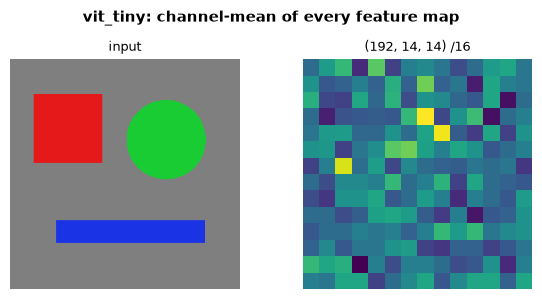

In [22]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [23]:
import sys
import numpy as np
import matplotlib.pyplot as plt

Parameters: 21,665,664
Embed dim : 384
pooled_output : torch.Size([1, 384])
patch_tokens  : torch.Size([1, 196, 384])
feature_maps  : torch.Size([1, 384, 14, 14])
Attention maps: 12 layers
  Layer 0 attn: torch.Size([1, 6, 197, 197])


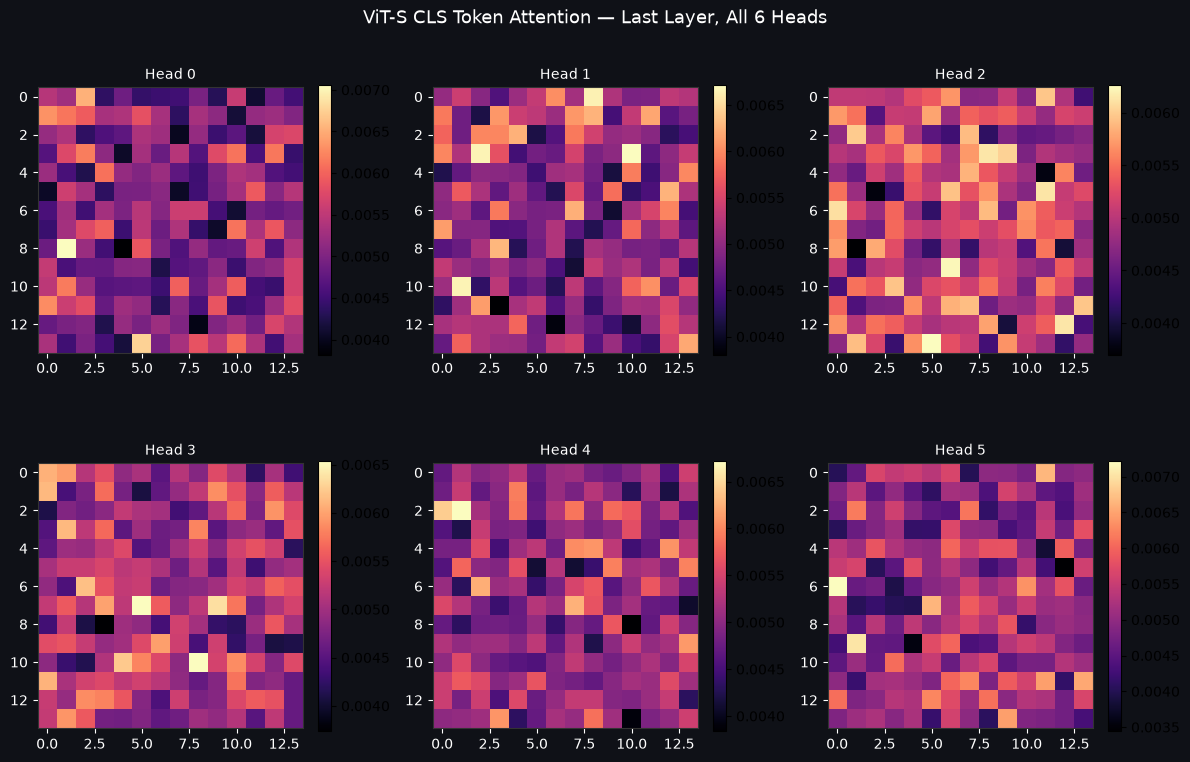


Different heads specialise in different spatial regions of the image.


In [24]:
import sys

import torch

# Build a ViT-Small and run a forward pass
backbone = build_vision_backbone('vit_small', img_size=224, return_all_attn=True)
backbone.eval()
print(f'Parameters: {backbone.num_parameters():,}')
print(f'Embed dim : {backbone.embed_dim}')

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print(f'pooled_output : {out.pooled_output.shape}')    # [1, 384]
print(f'patch_tokens  : {out.patch_tokens.shape}')     # [1, 196, 384]
print(f'feature_maps  : {out.feature_maps[0].shape}')  # [1, 384, 14, 14]
print(f'Attention maps: {len(out.attentions)} layers')
print(f'  Layer 0 attn: {out.attentions[0].shape}')    # [1, 6, 197, 197]

# Visualise attention from CLS token to patches (head 0, last layer)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('ViT-S CLS Token Attention — Last Layer, All 6 Heads', color='white', fontsize=13)

last_attn = out.attentions[-1][0]  # [H, N+1, N+1]
cls_attn = last_attn[:, 0, 1:]     # CLS→patches: [H, N]
cls_attn = cls_attn.reshape(-1, 14, 14).numpy()

for i, ax in enumerate(axes.flat):
    ax.set_facecolor('#0f1117')
    if i < 6:
        im = ax.imshow(cls_attn[i], cmap='magma', interpolation='nearest')
        ax.set_title(f'Head {i}', color='white', fontsize=10)
        plt.colorbar(im, ax=ax, fraction=0.046)
    ax.tick_params(colors='white')
    for sp in ax.spines.values():
        sp.set_edgecolor('#333')

plt.tight_layout()

plt.show()
print('\nDifferent heads specialise in different spatial regions of the image.')

## References

### Primary
1. A. Dosovitskiy et al., "An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale," *ICLR 2021*. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)
2. X. Zhai et al., "Scaling Vision Transformers to 22 Billion Parameters," *ICML 2022*. [arXiv:2302.05442](https://arxiv.org/abs/2302.05442)

### Related Works
3. A. Vaswani et al., "Attention Is All You Need," *NeurIPS 2017*. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762) — Original Transformer
4. J. Devlin et al., "BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding," *NAACL 2019*. [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)
5. H. Touvron et al., "Training data-efficient image transformers & distillation through attention," *ICML 2021*. [arXiv:2012.12877](https://arxiv.org/abs/2012.12877) — DeiT
6. Z. Liu et al., "Swin Transformer: Hierarchical Vision Transformer using Shifted Windows," *ICCV 2021*. [arXiv:2103.14030](https://arxiv.org/abs/2103.14030)
7. K. He et al., "Masked Autoencoders Are Scalable Vision Learners," *CVPR 2022*. [arXiv:2111.06377](https://arxiv.org/abs/2111.06377) — MAE pre-training for ViT